# Peggle DQN - Mid-Stage Investigation and Improved Agent

## 1. Project Introduction

The final project has two proposed objectives: clear all orange pegs, and later clear every peg with few shots. **Only the orange-target DQN is implemented here.** It plays one original Level 1 layout with 77 fixed peg positions, 25 newly randomized orange targets per game, 52 blue pegs, 21 angles, and ten shots.

The first ten-peg fixture was solved in one shot. The first full-board DQN then collapsed to +42 degrees: its archived evaluation cleared only 4.16% of oranges versus 65.52% for random shooting. This notebook investigates that failure, measures a small set of changes, selects a checkpoint on validation games, and reports separate final evaluation games. The original checkpoints and result files remain untouched.

The aim is an understandable application of **standard Stable-Baselines3 DQN**, not a new RL algorithm. All figures and tables below come from real simulation or saved measurements. One main notebook imports the supporting Python files.

### Setup and saved versus new results

Select the project's virtual-environment kernel and run from the Final Project folder. Install dependencies with that interpreter using `python -m pip install -r requirements.txt`. After supporting files change, use **Restart Kernel and Run All**.

By default this notebook **loads** the selected model and saved results; it never automatically starts training. Set `RUN_TRAINING = True` for a new experiment. Set `RESUME_TRAINING = True` as well to continue `notebook_run/last_model.zip`. `TRAINING_TIMESTEPS` then means **additional shots**, not the desired cumulative total. Change `RUN_NAME` to keep a separate experiment.

Training and checkpoint evaluation are reusable functions in `levels/train_dqn.py`. The replay-buffer `.pkl` files are generated training experience used for continuation; they are not additional source code or settings that must be edited.

In [1]:
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image, HTML
from stable_baselines3 import DQN

from levels.config_rl import (RLConfig, DQN_SETTINGS, SEED, VALIDATION_SEED, TEST_SEED,
    IMPROVED_MODELS_DIR, IMPROVED_RESULTS_DIR, BEST_MODEL_PATH)
from levels.peggle_env import PeggleEnv
from levels.train_dqn import train_agent, record_experiment, select_best_experiment
from levels.evaluate import evaluate_agents, angle_diagnostic, greedy_diagnostic
from levels.visualize_data import export_data, plot_gameplay, record_gameplay

RUN_TRAINING = False
RESUME_TRAINING = False
TRAINING_TIMESTEPS = 10_000
RUN_NAME = "notebook_run"
RUN_EVALUATION = False

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
results_dir = IMPROVED_RESULTS_DIR
selection = pd.read_csv(results_dir / "selected_model.csv").iloc[0]
config = RLConfig(observation=selection.observation,
                  empty_shot_penalty=float(selection.empty_shot_penalty))
print("Saved selected experiment:", selection.experiment)
print("Full board:", config.n_pegs, "pegs;", config.n_orange, "orange targets")
print("Observation:", config.n_pegs * config.features_per_peg + 1, "values; angles:", config.n_actions)
print("RUN_TRAINING:", RUN_TRAINING, "RUN_EVALUATION:", RUN_EVALUATION)

Saved selected experiment: compact
Full board: 77 pegs; 25 orange targets
Observation: 155 values; angles: 21
RUN_TRAINING: False RUN_EVALUATION: False


## 2. Dataset Description

`local/PegglePy-main/levels/Level 1.lvl` stores **77 coordinate pairs**, without colors or hit labels. We preserve archive order and PegglePy's normal centering translation: x shifts by -62.5 and y by +51 pixels on the 1200-by-900 screen. Positions never move between games. The exported table includes archived and centered values.

PegglePy's `createPegColors()` chooses **25 distinct orange pegs** on this level. Our reset function uses Gymnasium's NumPy generator and `choice(..., replace=False)` to select that number. Every other peg is blue; green power-ups are omitted. Colors stay fixed for a game, while hit flags change. A seeded run reproduces the sequence; episode resets without a new seed continue the generator.

**Experience is generated by gameplay**, not loaded from a labeled dataset. A shot produces state, action, measured reward, next state and termination. DQN stores these transitions in replay memory.

In [2]:
board_data, original_data = export_data(results_dir, seed=SEED, config=config)
second_arrangement = pd.read_csv(results_dir / "board_arrangement_2.csv")
print("Original Level 1 records:", len(original_data))
display(original_data.head(8))
display(board_data.head(10))
display(board_data.groupby("color").size().rename("peg_count").to_frame())

Original Level 1 records: 77


,peg_id,archive_x,archive_y,x,y,color_before_assignment,initial_is_hit,color_stored_in_file
0,0,162.0,343.0,99.5,394.0,blue,False,False
1,1,168.0,373.0,105.5,424.0,blue,False,False
2,2,173.0,404.0,110.5,455.0,blue,False,False
3,3,178.0,434.0,115.5,485.0,blue,False,False
4,4,182.0,464.0,119.5,515.0,blue,False,False
5,5,187.0,494.0,124.5,545.0,blue,False,False
6,6,191.0,525.0,128.5,576.0,blue,False,False
7,7,194.0,555.0,131.5,606.0,blue,False,False


,peg_id,x,y,color,is_hit,is_visible,radius
0,0,99.5,394.0,blue,False,True,25.0
1,1,105.5,424.0,blue,False,True,25.0
2,2,110.5,455.0,blue,False,True,25.0
3,3,115.5,485.0,blue,False,True,25.0
4,4,119.5,515.0,orange,False,True,25.0
5,5,124.5,545.0,orange,False,True,25.0
6,6,128.5,576.0,blue,False,True,25.0
7,7,131.5,606.0,blue,False,True,25.0
8,8,138.5,636.0,orange,False,True,25.0
9,9,146.5,665.0,blue,False,True,25.0


,peg_count
color,
blue,52
orange,25


## 3. Data Visualization

The first figure shows the original game-centered coordinates before color assignment. The second shows two consecutive seeded resets: the same 77 positions, with different sets of 25 orange targets. Assertions below verify that positions match and colors change.

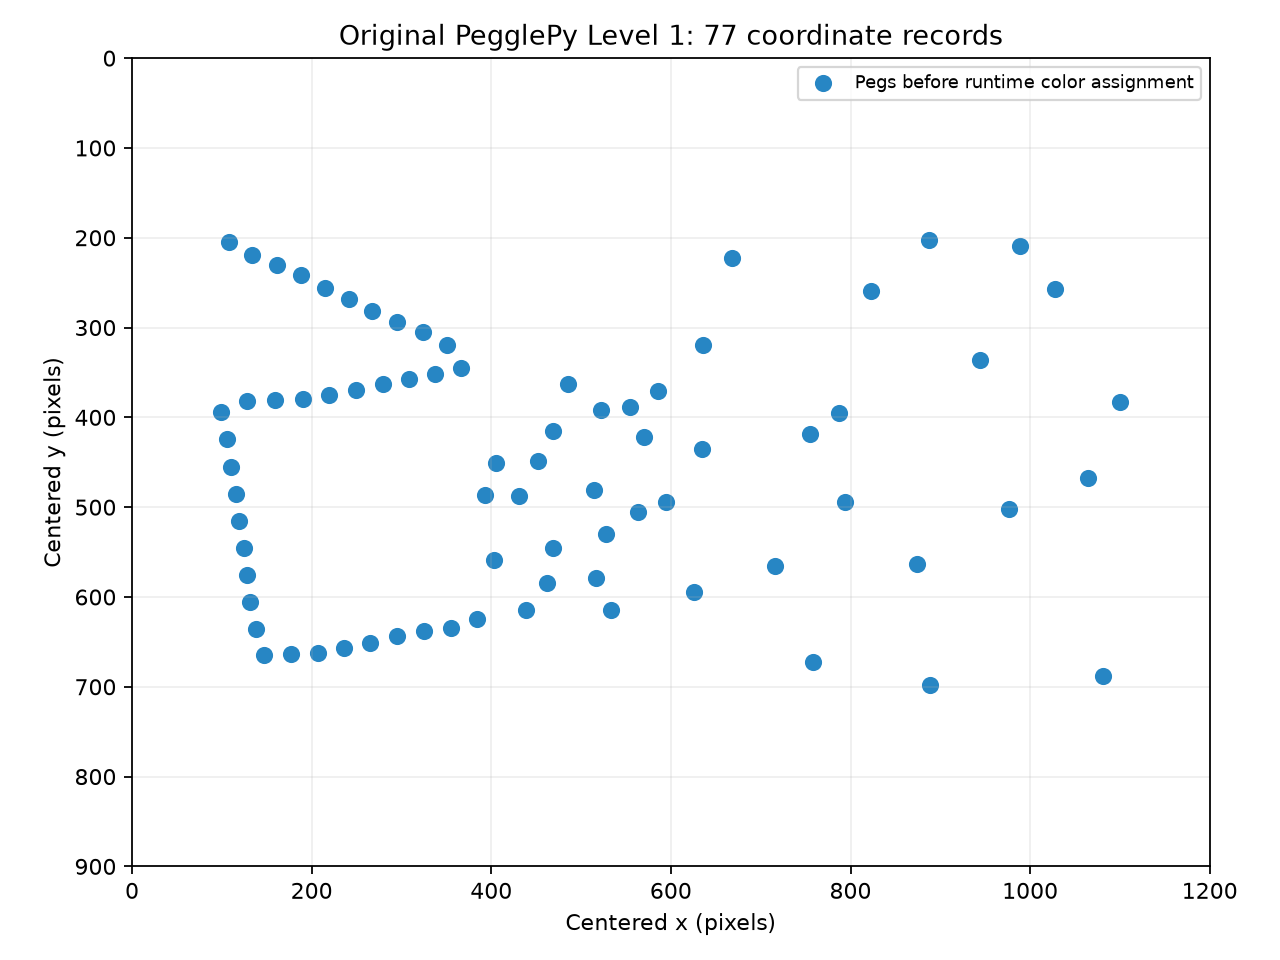

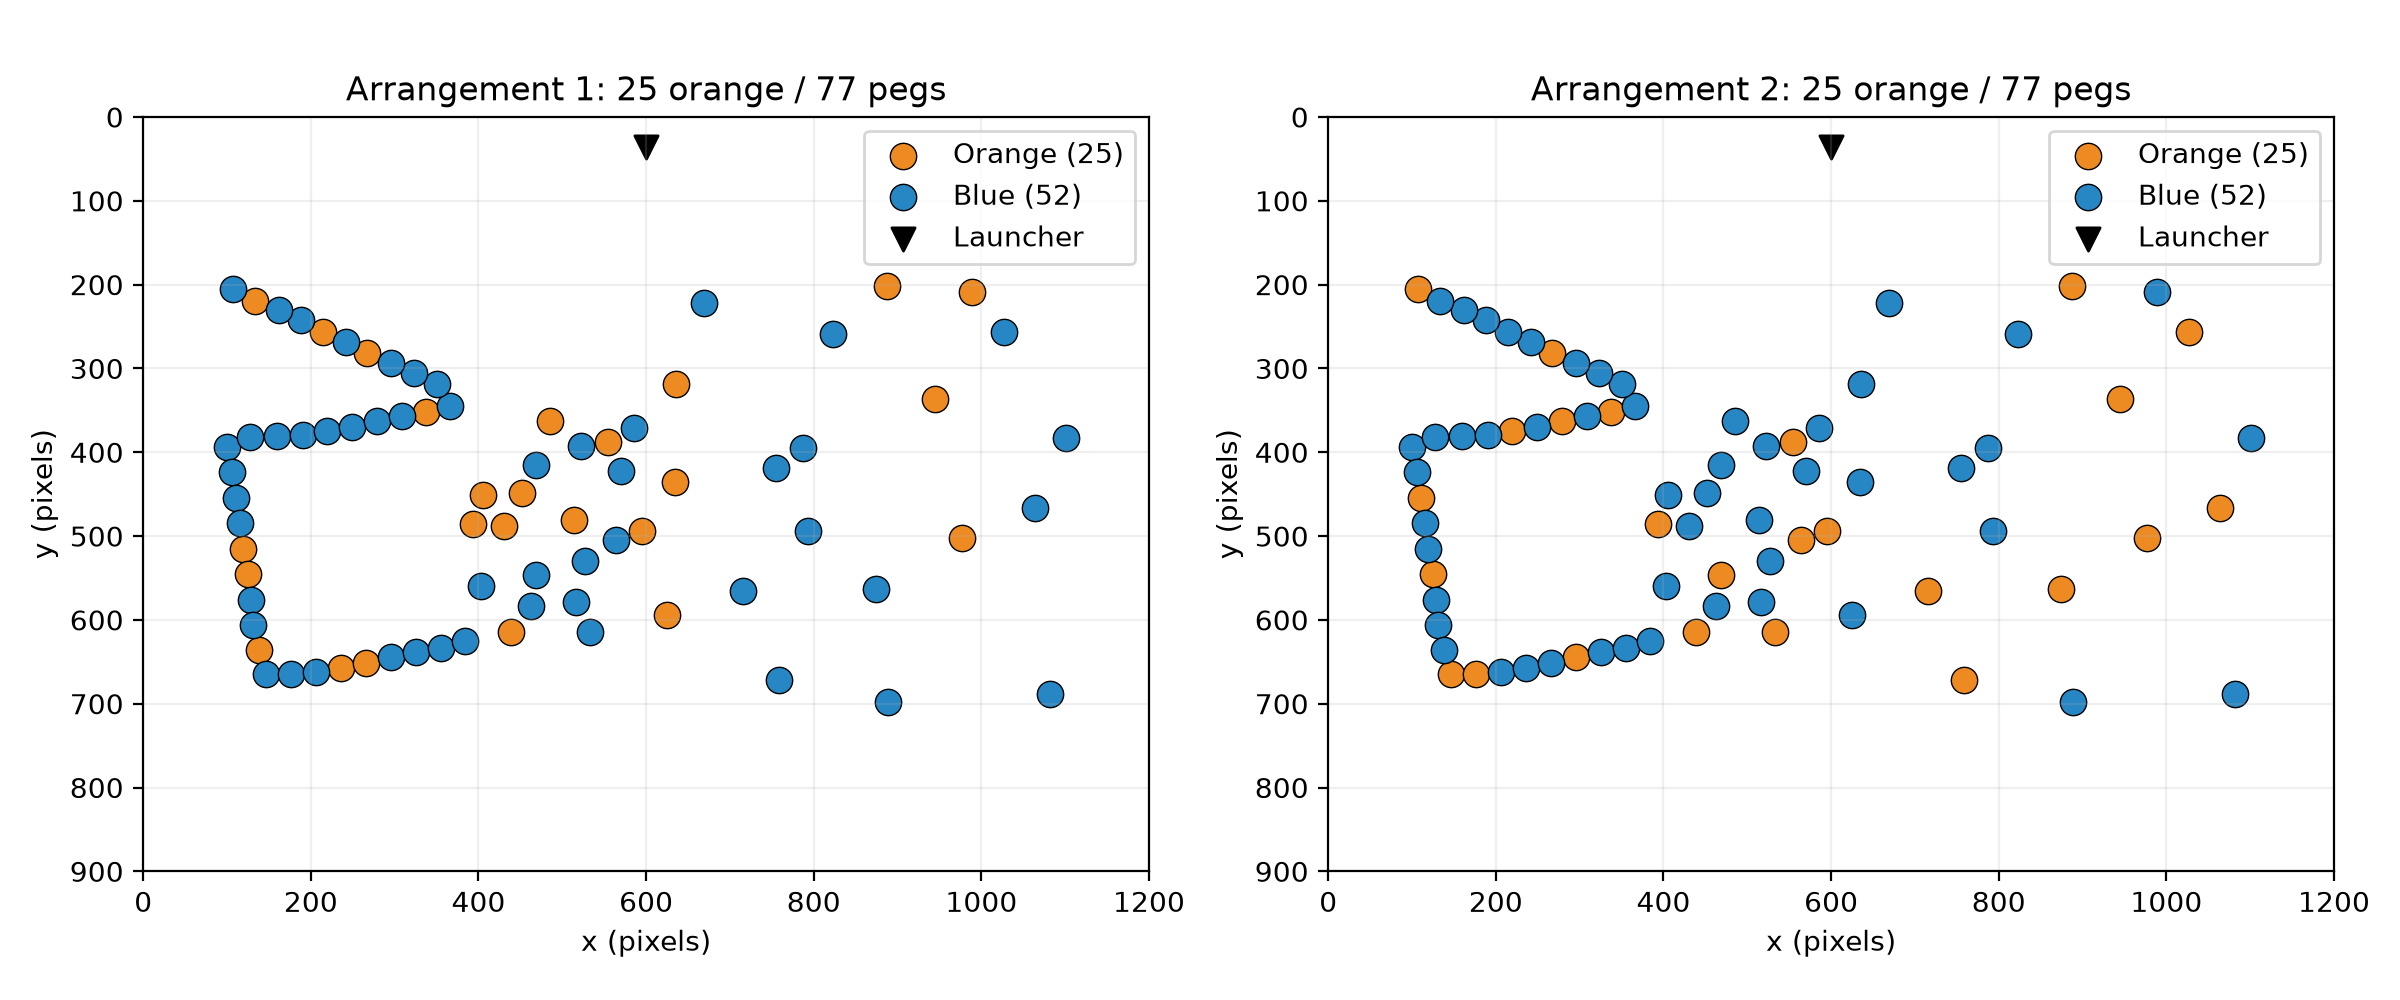

Color assignments changed at 30 peg slots.


In [3]:
display(Image(filename=str(results_dir / "original_board_visualization.png")))
display(Image(filename=str(results_dir / "random_arrangements.png")))
np.testing.assert_array_equal(board_data[["x", "y"]], second_arrangement[["x", "y"]])
assert len(board_data) == 77
assert (board_data.color == "orange").sum() == 25
assert (second_arrangement.color == "orange").sum() == 25
print("Color assignments changed at", int((board_data.color != second_arrangement.color).sum()), "peg slots.")

## 4. Data Preprocessing

The original representation has four features per peg: normalized x, normalized y, orange indicator, hit indicator, plus remaining shots / 10: **309 values**.

The tested compact representation keeps orange and hit indicators in the same stable peg order, plus remaining shots / 10: **155 values**. Since the physical positions never change, each index already identifies a position. Removing repeated coordinates preserves the changing state information and reduces the input size. This is specific to one fixed level; it would need reconsideration for different layouts.

Both representations are numerical `float32` arrays in [0,1]. Hit pegs keep their slots, and their hit flag identifies their removal between shots. The original 309-input model is evaluated with its original representation; the compact model gets its 155-input representation. Neither model's network is resized after training.

In [4]:
env = PeggleEnv(config)
obs, info = env.reset(seed=SEED)
full_obs = env._observation("full")
compact_obs = env._observation("compact")
assert full_obs.shape == (309,) and compact_obs.shape == (155,)
np.testing.assert_array_equal(compact_obs[:-1], full_obs[:-1].reshape(77, 4)[:, 2:].flatten())
display(pd.DataFrame(compact_obs[:-1].reshape(77, 2), columns=["is_orange", "is_hit"]).head(12))
print("Selected model observation:", obs.shape, obs.dtype)
next_obs, reward, terminated, truncated, shot_info = env.step(10)
display(pd.DataFrame([shot_info]))
print("Measured straight-down reward:", reward)
expected = 10 * shot_info["new_orange_cleared"] - 1
if shot_info["new_orange_cleared"] == 0:
    expected -= config.empty_shot_penalty
if shot_info["success"]:
    expected += 25
assert reward == expected
env.close()

,is_orange,is_hit
0,0.0,0.0
1,0.0,0.0
2,0.0,0.0
3,0.0,0.0
4,1.0,0.0
5,1.0,0.0
6,0.0,0.0
7,0.0,0.0
8,1.0,0.0
9,0.0,0.0


Selected model observation: (155,) float32


,orange_initial,orange_remaining,orange_cleared,success,shots_remaining,shots_used,simulation_timeouts,stuck_removals,new_orange_cleared,angle_degrees,simulation_frames,shot_timed_out,terminal_reason
0,25,18,7,False,9,1,0,3,7,0.0,2396,False,None


Measured straight-down reward: 69.0


### Environment investigation and collision correction

The pre-change suite passed 18 tests, but additional inspection exposed a bookkeeping bug: the wrapper could flag all swept-path candidates as hit even though the response stopped at the first impact. A new two-peg regression test failed on that implementation. The wrapper now marks only pegs at the collision response's actual contact position. The regression passes. This also avoids rewarding a candidate when the upstream response finds no impact.

PegglePy's `Ball.update` and collision function bodies, fixed `dt=1.0`, launch force, gravity, velocity cap, shot limit, and level geometry remain unchanged. Arithmetic tests independently check free flight at two angles and a known isolated collision. These checks do not establish exact agreement with an entire graphical game: the wrapper's update scheduling, sampled collisions, omitted bucket and power-ups, and deterministic stuck-removal timer remain limitations.

Already-hit pegs stay solid within a shot, except stuck removals, and disappear before the next shot. Rewards count changes in orange hit flags, so a cleared target cannot earn its reward twice. Episode termination is success or ten used shots. The old full-board results are archived; all final baselines below are reevaluated under the corrected implementation.

### Shooting-angle diagnostic, separate from learning

For each of three fixed seeds, the diagnostic resets to the same arrangement before testing each of the 21 actions. This is simulator inspection, not expert action labels. The table records newly hit oranges, reward, frames, and actual position at frame 10; different positions confirm that actions produce different paths. Training never calls this diagnostic to choose an action.

seed,42,43,44
angle_degrees,,,
-60.0,2,6,1
-54.0,9,10,6
-48.0,4,4,3
-42.0,8,8,5
-36.0,4,7,5
-30.0,4,4,5
-24.0,2,0,3
-18.0,4,3,4
-12.0,4,1,4


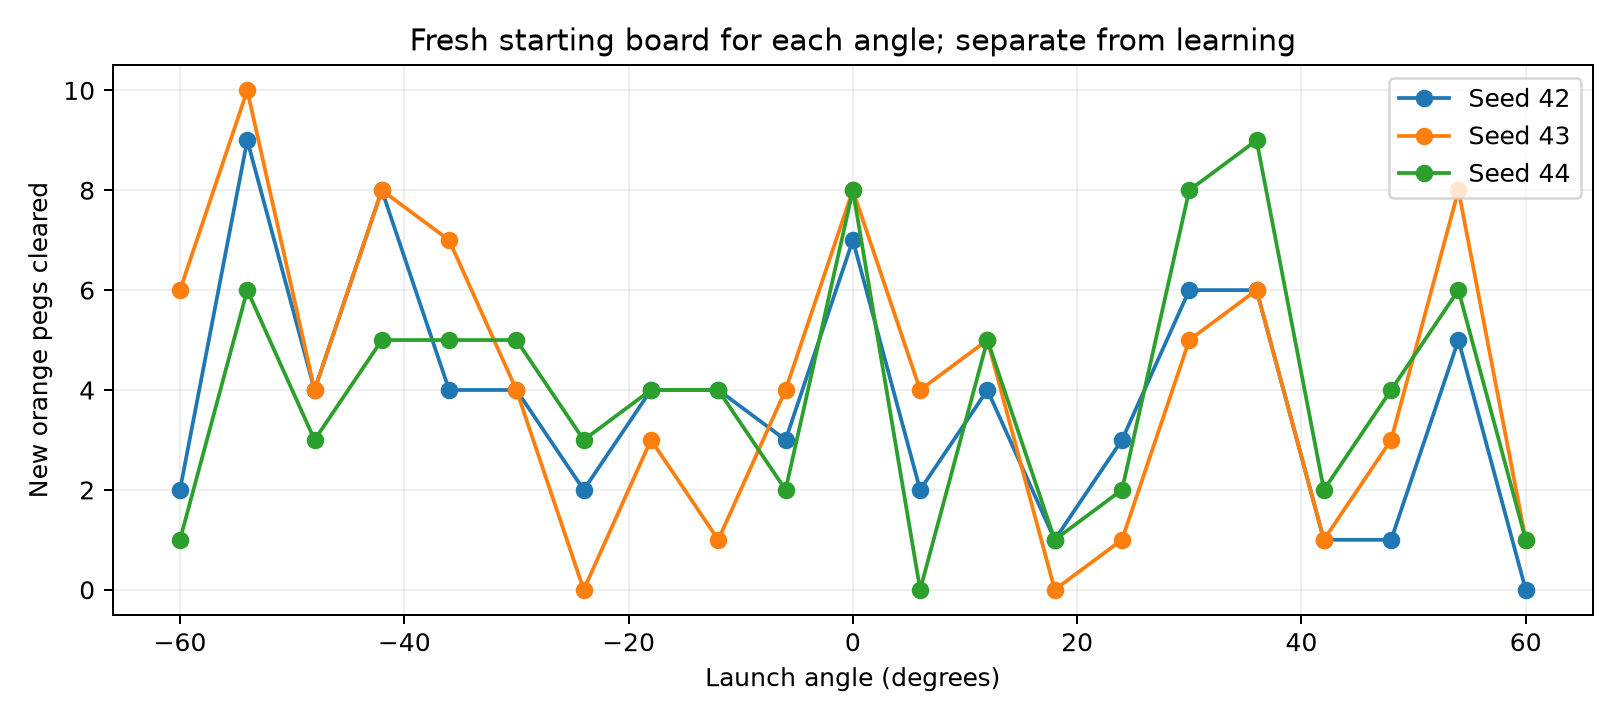

,min_orange,max_orange,distinct_initial_paths
seed,,,
42,0,9,21
43,0,10,21
44,0,9,21


In [5]:
diagnostic_path = results_dir / "angle_diagnostic.csv"
if not diagnostic_path.exists():
    angle_diagnostic(results_dir=results_dir)
angle_results = pd.read_csv(diagnostic_path)
display(angle_results.pivot(index="angle_degrees", columns="seed", values="orange_cleared"))
display(Image(filename=str(results_dir / "angle_diagnostic.png")))
display(angle_results.groupby("seed").agg(min_orange=("orange_cleared", "min"),
    max_orange=("orange_cleared", "max"), distinct_initial_paths=("x_at_frame_10", "nunique")))

### Small feasibility diagnostic

A separate greedy probe tries all 21 angles on copies of the current cleared state and plays the angle with the most immediate orange hits. It uses simulator lookahead unavailable to DQN and is **not** a learned agent or an optimal solver. It is limited to three games for cost. A win proves feasibility for that arrangement; a loss does not prove impossibility. The shot limit and final target count remain ten and 25.

In [6]:
greedy_path = results_dir / "greedy_diagnostic_episodes.csv"
if not greedy_path.exists():
    greedy_diagnostic(results_dir=results_dir)
greedy_results = pd.read_csv(greedy_path)
display(greedy_results)
print("Greedy diagnostic wins:", int(greedy_results.success.sum()), "/", len(greedy_results))

,seed,success,shots_used,orange_cleared,orange_remaining,orange_cleared_pct
0,30042,False,10,24,1,96.0
1,30043,True,7,25,0,100.0
2,30044,False,10,23,2,92.0


Greedy diagnostic wins: 1 / 3


## 5. DQN Implementation and Training

All experiments use **standard SB3 DQN with `MlpPolicy` and hidden layers [64,64]**. Actions remain -60 to +60 degrees in six-degree increments. The baseline reward is `10 x newly hit oranges - 1 per shot + 25 on success`. One controlled experiment adds -5 when no orange is newly hit. No new algorithm, action oracle, custom PyTorch training, or extra game objective is introduced.

We compare a corrected-environment control, a lower learning rate (0.0003 instead of 0.001), compact observations, and then the additional empty-shot penalty. Replay capacity 20,000, batch size 64, discount 0.99, 200 initial warmup shots, one update per four shots, target interval 500, and epsilon decay from 1 to 0.05 over the first 60% of the budget are retained. The CSV gives actual budgets and settings; this is a small, predefined investigation rather than automatic hyperparameter optimization.

The old network's large Q estimates for repeatedly unrewarding +42-degree shots show inaccurate learned values. The environment diagnostic shows useful reward differences. Longer training, state representation and checkpoint retention are tested explanations; we do not claim to have isolated a single universal cause.

In [7]:
from gymnasium.utils.env_checker import check_env as gymnasium_check
from stable_baselines3.common.env_checker import check_env as sb3_check
gymnasium_check(PeggleEnv(config), skip_render_check=True)
sb3_check(PeggleEnv(config), warn=True)
experiments = pd.read_csv(results_dir / "experiments.csv")
display(experiments[["experiment", "input_size", "learning_rate", "empty_shot_penalty",
    "total_training_shots", "best_step", "validation_clearance_pct",
    "validation_win_rate_pct", "validation_distinct_angles"]].round(3))
print("Selection criterion: mean orange clearance, then win rate, on validation games only.")

,experiment,input_size,learning_rate,empty_shot_penalty,total_training_shots,best_step,validation_clearance_pct,validation_win_rate_pct,validation_distinct_angles
0,control,309,0.001,0,10000,10000,74.0,0.0,8
1,lower_lr,309,0.000,0,25000,25000,75.6,0.0,6
2,empty_penalty,155,0.000,5,25000,25000,86.8,0.0,6
3,compact,155,0.000,0,50000,45000,94.8,40.0,4


Selection criterion: mean orange clearance, then win rate, on validation games only.


### Training continuation and model selection

Checkpoints are saved every 5,000 shots and at a run's end. Each is evaluated deterministically on the same ten randomized validation games (seed 20042 onward). The best checkpoint maximizes orange clearance, breaking ties by win rate. It can be earlier than the final checkpoint. Final reporting uses a separate set of 100 arrangements (seed 50042 onward), never used to choose checkpoints.

Continuation uses SB3's `DQN.load(..., env=...)`, `load_replay_buffer`, and `learn(..., reset_num_timesteps=False)`. Optimizer state, learned weights, replay and cumulative timesteps are retained. Episode logs append instead of starting again at zero. A resumed segment starts a fresh reproducible environment sequence, and SB3 recomputes exploration for the extended budget, so this is not bit-exact continuation of a partially played game. Changing representation or rewards requires a separate experiment folder.

`last_model.zip` and `best_model.zip` have adjacent replay `.pkl` files. Intermediate ZIPs keep model snapshots; if resumed without replay, the helper explicitly collects fresh warmup experience. Fresh runs refuse to overwrite existing logs. The original small-board and first full-board artifacts remain protected.

References: [SB3 save/load examples](https://stable-baselines3.readthedocs.io/en/master/guide/examples.html) and [DQN API](https://stable-baselines3.readthedocs.io/en/master/modules/dqn.html).

In [8]:
if RUN_TRAINING:
    run_model = IMPROVED_MODELS_DIR / RUN_NAME / "last_model.zip"
    run_results = IMPROVED_RESULTS_DIR / RUN_NAME
    settings = dict(DQN_SETTINGS)
    settings["learning_rate"] = float(selection.learning_rate)
    trained_model, training_log = train_agent(
        TRAINING_TIMESTEPS, config=config, dqn_settings=settings,
        model_path=run_model, results_dir=run_results,
        resume_from=run_model if RESUME_TRAINING else None, verbose=0)
    record_experiment(RUN_NAME, config, trained_model, training_log)
    select_best_experiment()
    model = DQN.load(run_model.parent / "best_model.zip", device="cpu")
    evaluation_dir = run_results
    print("Showing new training and this run's measured best checkpoint.")
else:
    run_results = IMPROVED_RESULTS_DIR / selection.experiment
    model = DQN.load(BEST_MODEL_PATH, device="cpu")
    training_log = pd.read_csv(run_results / "training_episodes.csv")
    evaluation_dir = IMPROVED_RESULTS_DIR
    print("Showing previously saved training and the validation-selected model:", selection.experiment)
print("Selected checkpoint's training steps:", model.num_timesteps)
total_steps = trained_model.num_timesteps if RUN_TRAINING else int(selection.total_training_shots)
print("Total shots trained in this experiment:", total_steps)
print("Last completed-episode timestep:", int(training_log.timesteps.max()))
display(pd.read_csv(run_results / "training_settings.csv"))

Showing previously saved training and the validation-selected model: compact
Selected checkpoint's training steps: 45000
Total shots trained in this experiment: 50000
Last completed-episode timestep: 49997


,starting_step,additional_shots,seed,observation,input_size,orange_targets,empty_shot_penalty,learning_rate,gamma,buffer_size,batch_size,learning_starts,exploration_fraction,final_epsilon,network,validation_seed,validation_episodes
0,0,25000,42,compact,155,25,0,0.0003,0.99,20000,64,200,0.6,0.05,64 64,20042,10
1,25000,25000,42,compact,155,25,0,0.0003,0.99,20000,64,200,0.6,0.05,64 64,20042,10


## 6. Preliminary Results

### Training progress and deterministic checkpoints

Training curves include epsilon-greedy exploratory actions. The completed-episode CSV records return, clearance percentage, success, shots, initial target count, timeouts and stuck removals. A partial episode at a budget boundary is not counted as completed.

Checkpoint curves show deterministic policies on a fixed validation set. They can deteriorate even when a smoothed training curve looks promising. The selected checkpoint's step and the experiment's final budget are shown separately. Returns across different reward rules should not be compared directly; clearance is the common selection metric.

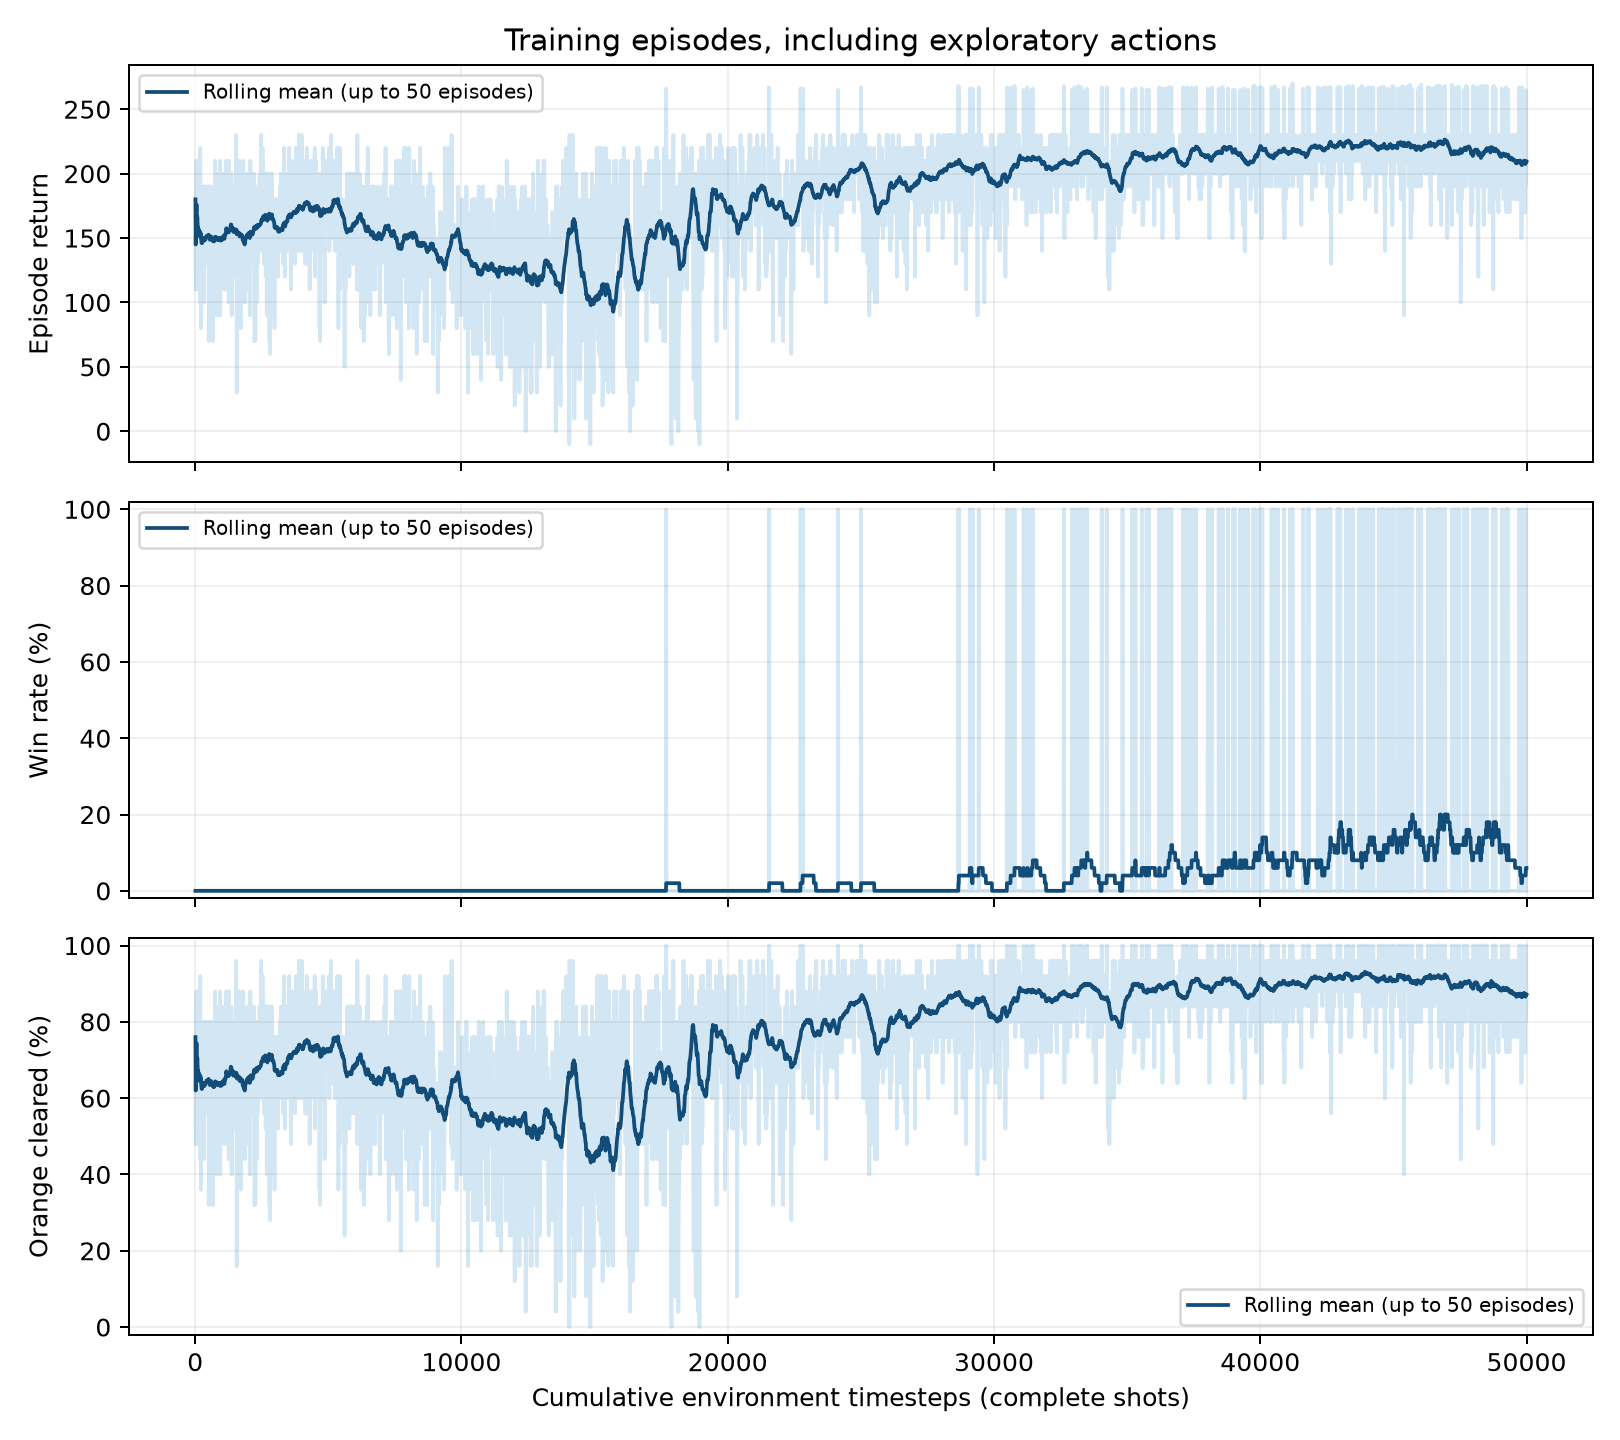

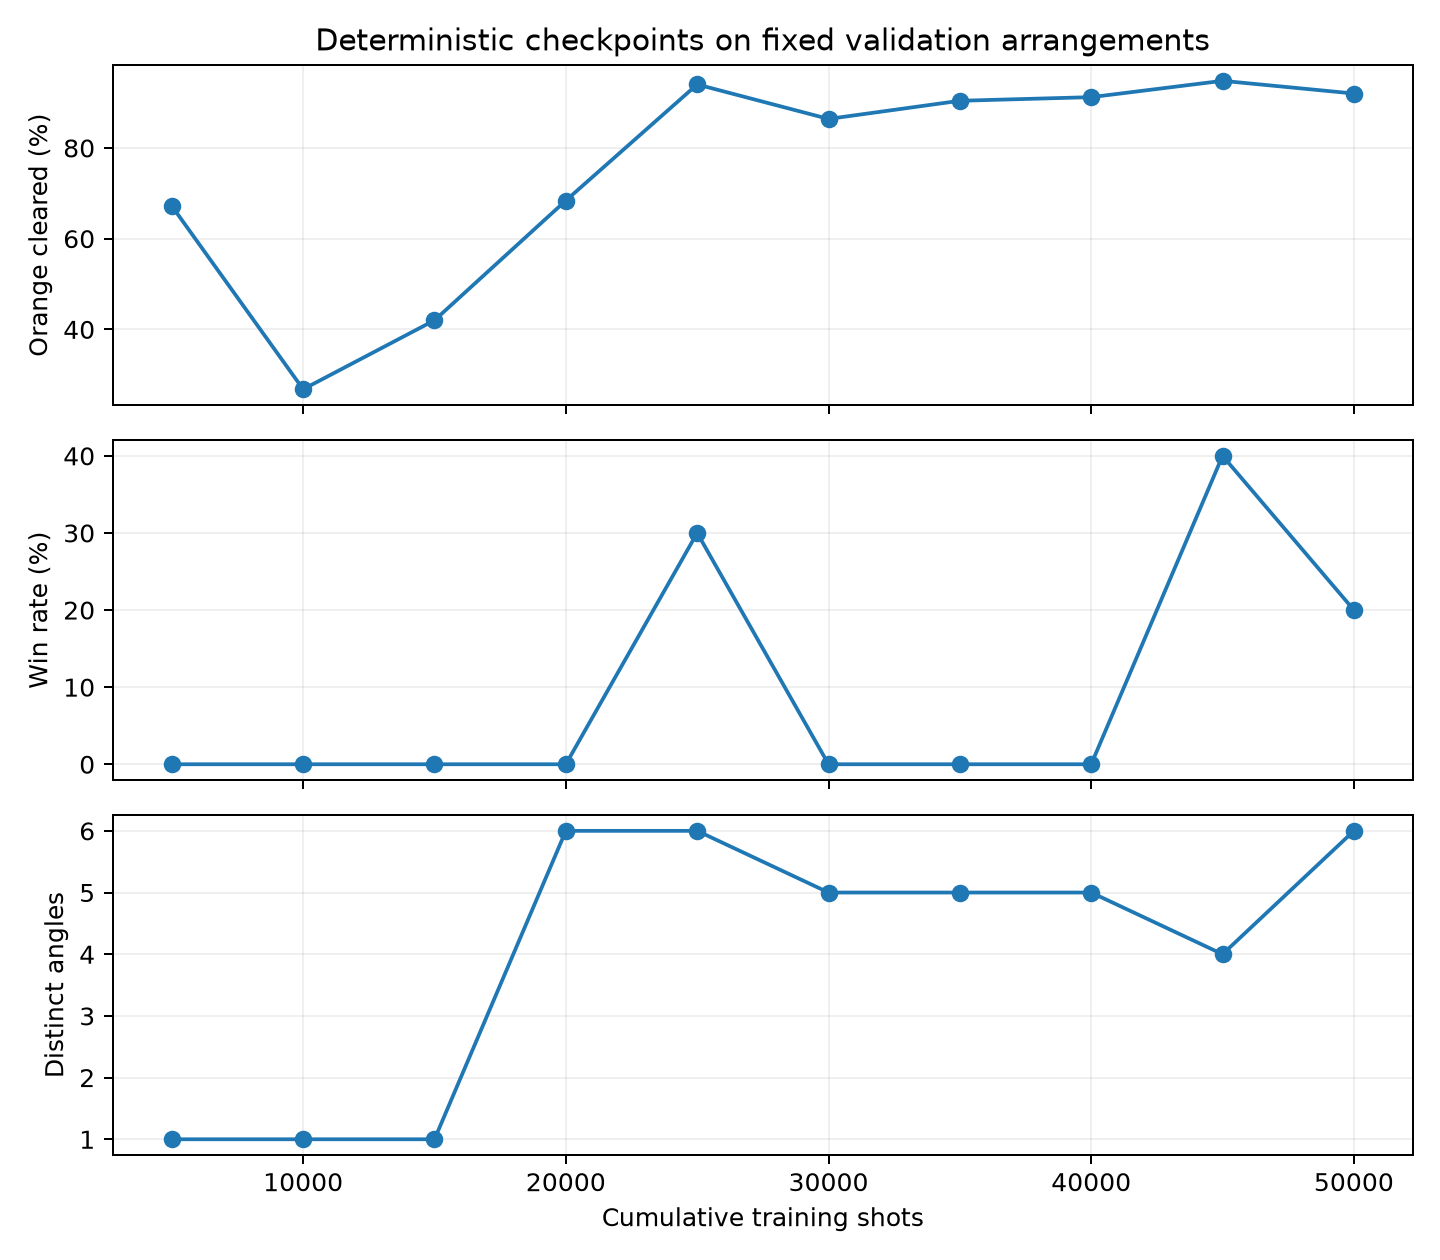

,timesteps,orange_cleared_pct,success_rate_pct,avg_orange_remaining,mean_episode_reward,distinct_angles,most_common_angle,most_common_angle_pct,is_best
0,5000,67.2,0.0,8.2,158.0,1,-60.0,100.000,False
1,10000,26.8,0.0,18.3,57.0,1,-42.0,100.000,False
2,15000,42.0,0.0,14.5,95.0,1,6.0,100.000,False
3,20000,68.4,0.0,7.9,161.0,6,-18.0,75.000,False
4,25000,94.0,30.0,1.5,233.0,6,-18.0,43.158,False
5,30000,86.4,0.0,3.4,206.0,5,-18.0,36.000,False
6,35000,90.4,0.0,2.4,216.0,5,-18.0,40.000,False
7,40000,91.2,0.0,2.2,218.0,5,-18.0,43.000,False
8,45000,94.8,40.0,1.3,238.1,4,-18.0,49.438,True
9,50000,92.0,20.0,2.0,225.5,6,-18.0,38.947,False


<Figure size 900x400 with 1 Axes>

In [9]:
display(Image(filename=str(run_results / "training_rewards.png")))
display(Image(filename=str(run_results / "checkpoint_evaluation.png")))
checkpoint_results = pd.read_csv(run_results / "checkpoint_evaluation.csv")
display(checkpoint_results[["timesteps", "orange_cleared_pct", "success_rate_pct",
    "avg_orange_remaining", "mean_episode_reward", "distinct_angles",
    "most_common_angle", "most_common_angle_pct", "is_best"]].round(3))
fig, ax = plt.subplots(figsize=(9,4))
for experiment in experiments.experiment:
    measured = pd.read_csv(results_dir / experiment / "checkpoint_evaluation.csv")
    ax.plot(measured.timesteps, measured.orange_cleared_pct, marker="o", label=experiment)
random_validation = pd.read_csv(results_dir / "validation_baselines.csv")
random_value = random_validation.set_index("agent").loc["random", "orange_cleared_pct"]
ax.axhline(random_value, linestyle="--", color="black", label="Random validation clearance")
ax.set(xlabel="Cumulative training shots", ylabel="Orange cleared (%)", title="Controlled validation comparisons")
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(results_dir / "experiment_comparison.png", dpi=180)
display(fig)
plt.close(fig)

### Final comparison on separate matched arrangements

All four policies use identical starting arrangements, the corrected physics, 25 oranges, the same reward rule and ten-shot budget. The original full-board DQN is reevaluated with its 309-input representation; its archived rewards are not mixed with current results. The random baseline uses an independent action generator, and the fixed-angle baseline always shoots at 0 degrees.

We report wins, win rate, average oranges cleared and percentage, average oranges remaining, shots conditioned on success, return, and angle diversity. No wins means successful-game shots are **N/A**. Multiple angles alone do not prove intelligent adaptation; matched clearance and win results provide the useful evidence. This remains one training seed and one physical level.

Loaded the previously measured 100-game comparison.


,agent,episodes,successes,success_rate_pct,avg_orange_cleared,orange_cleared_pct,avg_orange_remaining,avg_shots_success,avg_shots_all,mean_episode_reward,distinct_angles,most_common_angle,most_common_angle_pct,simulation_timeouts
0,DQN,100,12,12.0,23.15,92.60,1.85,7.917,9.75,224.75,5,-18.0,44.513,0
1,Random,100,0,0.0,16.28,65.12,8.72,N/A,10.00,152.80,21,-12.0,6.200,0
2,Straight down,100,0,0.0,13.06,52.24,11.94,N/A,10.00,120.60,1,0.0,100.000,0
3,Original DQN,100,0,0.0,0.96,3.84,24.04,N/A,10.00,-0.40,1,42.0,100.000,0


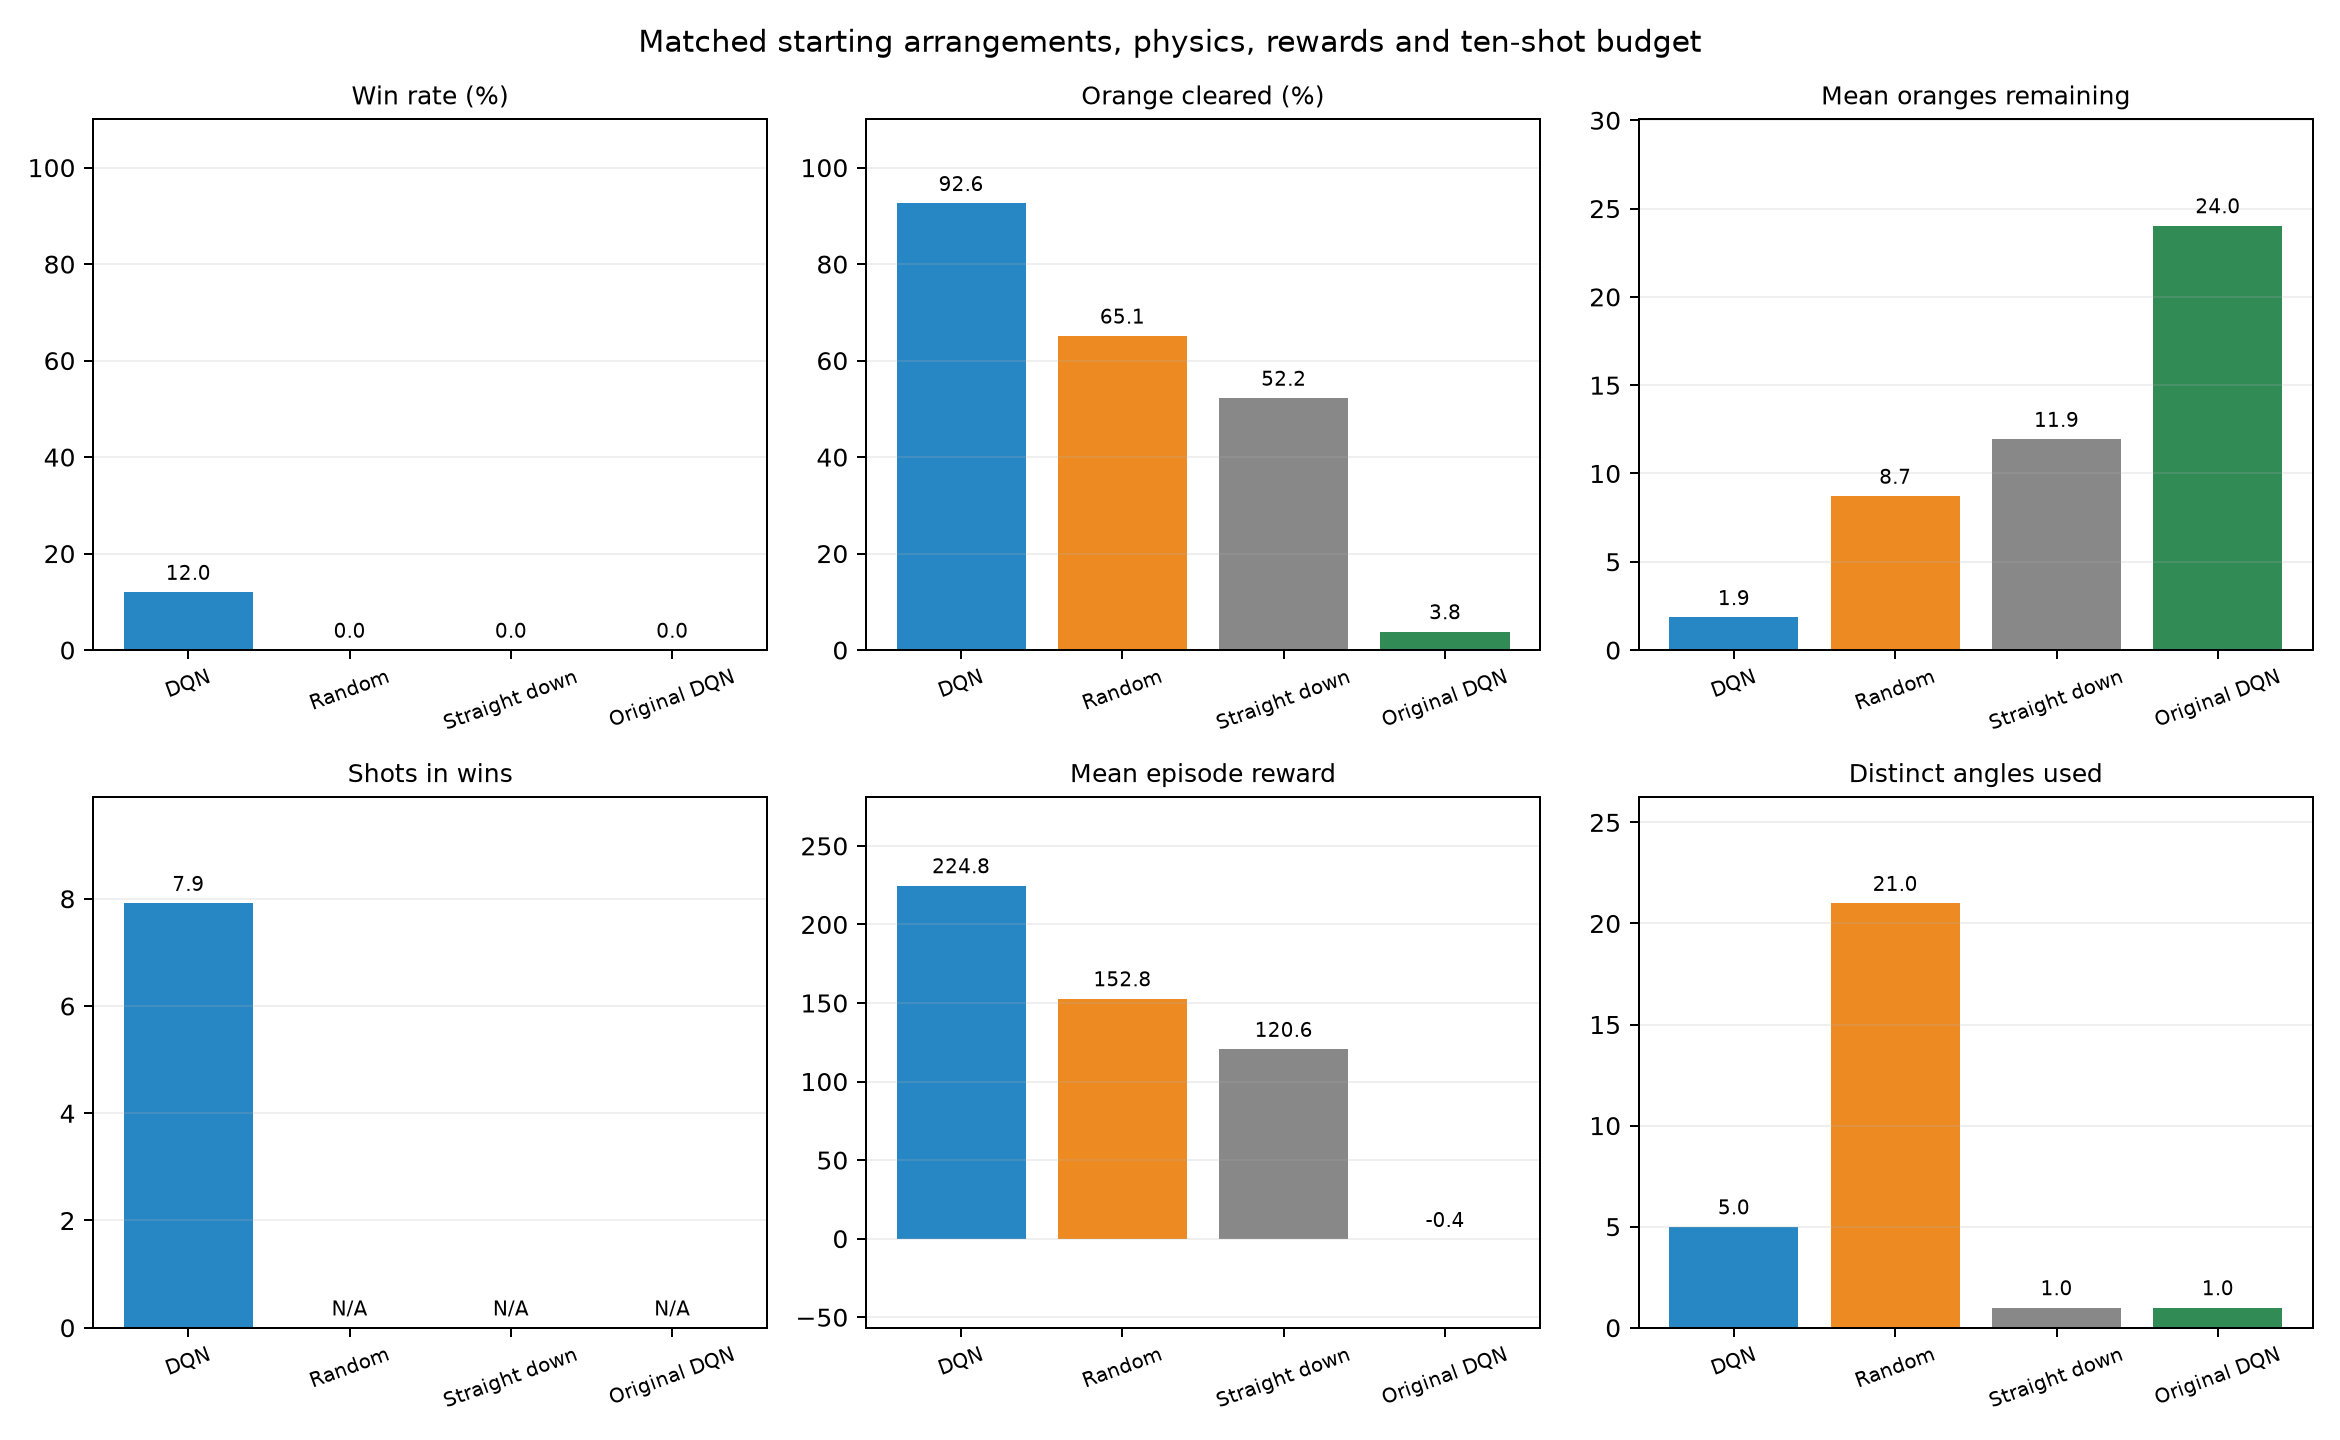

Matched arrangements: 100 Distinct: 100


In [10]:
evaluation_path = evaluation_dir / "evaluation_summary.csv"
if RUN_EVALUATION or RUN_TRAINING or not evaluation_path.exists():
    summary, evaluation_episodes = evaluate_agents(model=model, config=config,
        results_dir=evaluation_dir, episodes=100, seed=TEST_SEED, include_baselines=True)
    print("Computed a new 100-game comparison for each policy.")
else:
    summary = pd.read_csv(evaluation_path)
    evaluation_episodes = pd.read_csv(evaluation_dir / "evaluation_episodes.csv")
    print("Loaded the previously measured 100-game comparison.")
display(summary.round(3).fillna("N/A"))
display(Image(filename=str(evaluation_dir / "dqn_vs_random.png")))
arrangements = pd.read_csv(evaluation_dir / "evaluation_arrangements.csv")
paired = arrangements.pivot(index="episode", columns="agent", values="orange_peg_ids")
for agent in paired:
    assert paired[agent].equals(paired.DQN)
print("Matched arrangements:", len(paired), "Distinct:", paired.DQN.nunique())

### Interpretation from measured files

The text and angle counts below are generated from the saved results. A successful DQN episode is evidence of solving that particular randomized arrangement, not every possible arrangement or another level. Repeated choices can sometimes be useful because the board changes after a shot; constant ineffective repetition is checked through both angle logs and clearance.

In [11]:
values = summary.set_index("agent")
dqn, random_agent = values.loc["DQN"], values.loc["Random"]
comparison = "higher" if dqn.orange_cleared_pct > random_agent.orange_cleared_pct else "no higher"
display(Markdown(f"**Measured DQN:** {int(dqn.successes)} wins in {int(dqn.episodes)} games "
    f"({dqn.success_rate_pct:.1f}%), {dqn.orange_cleared_pct:.2f}% mean orange clearance, "
    f"{int(dqn.distinct_angles)} distinct angles. Clearance was {comparison} than random shooting "
    f"({random_agent.orange_cleared_pct:.2f}%). These are results for one selected run on one level."))
shot_log = pd.read_csv(evaluation_dir / "evaluation_shots.csv")
display(shot_log[shot_log.agent == "DQN"].angle_degrees.value_counts().rename("shots").to_frame())
print("Final evaluation timeouts:", int(summary.simulation_timeouts.sum()))
selected_shots = shot_log[shot_log.agent == "DQN"]
print("Distinct first-shot angles:", selected_shots[selected_shots.shot == 1].angle_degrees.nunique())
print("Distinct episode action sequences:", selected_shots.groupby("episode").action.apply(tuple).nunique())

**Measured DQN:** 12 wins in 100 games (12.0%), 92.60% mean orange clearance, 5 distinct angles. Clearance was higher than random shooting (65.12%). These are results for one selected run on one level.

,shots
angle_degrees,
-18.0,434
-60.0,351
0.0,102
36.0,87
-6.0,1


Final evaluation timeouts: 0
Distinct first-shot angles: 2
Distinct episode action sequences: 24


### Executed verification

The existing tests were retained and extended. The collision regression was observed failing before its fix. The suite checks reset/randomization, fixed positions, both observation representations, physical hits, rewards and empty-shot penalties, no duplicate orange rewards, termination, Gymnasium/DQN compatibility, checkpoint save/load, exact restored weights and optimizer state, replay continuity, appended history, measured best-checkpoint selection, four-agent board pairing, and recorded gameplay consistency.

A 256-shot smoke run followed by 128 additional resumed shots completed before the controlled experiments. Run the current suite from the project root with `python -m pytest levels/test_environment.py -q`. Tests are not a proof of full graphical-game fidelity or generalization.

At implementation verification, the full suite completed with **26 passed, 0 failed, and no warnings**. These checks were executed, not merely written.

## 7. Novel Solution and Future Work

The contribution is an inspectable connection between original game data, headless shot simulation, changing numerical state, standard DQN, controlled experiments, checkpoint selection and fair baselines. The original one-shot fixture is preserved as an initial experiment rather than presented as full Level 1 performance.

Remaining limitations include one training seed, ten validation games for selection, one fixed physical layout, no strict exclusion of all training arrangements from evaluation, numerical collision limitations, and the simplified stuck timer. More training is not guaranteed to improve the final policy, which is why intermediate checkpoints are retained. The greedy diagnostic has privileged simulator lookahead and is not a learned-policy result.

Optional staged training is reserved for a failure of the simpler changes; it is not needed merely to enlarge this implementation. The second all-peg objective, more levels, new algorithms, image inputs, automated tuning and extra game mechanics remain outside this stage.

## Visual Demonstration: Best Saved DQN Playing Peggle

The demonstration chooses a real winning episode from the final evaluation when available, otherwise the episode with the most oranges cleared. It then replays that exact seed using the selected DQN and verifies its outcome and action sequence against the saved shot log. This is an illustrative best episode, not a typical-game estimate; the full 100-game table is the performance evidence.

Each row shows shot number, selected angle, new orange hits, oranges remaining, shots remaining and measured reward. The ball path and frame-specific hit/removal states come from the actual simulator. No greedy actions are supplied to DQN.

,shot,angle_degrees,new_orange_cleared,orange_remaining,shots_remaining,reward
0,1,0.0,13,12,9,129.0
1,2,-60.0,4,8,8,39.0
2,3,-18.0,3,5,7,29.0
3,4,-18.0,1,4,6,9.0
4,5,-18.0,2,2,5,19.0
5,6,-18.0,1,1,4,9.0
6,7,36.0,1,0,3,34.0


Recorded evaluation episode 78, seed 50119: WIN; 0 orange pegs remained.


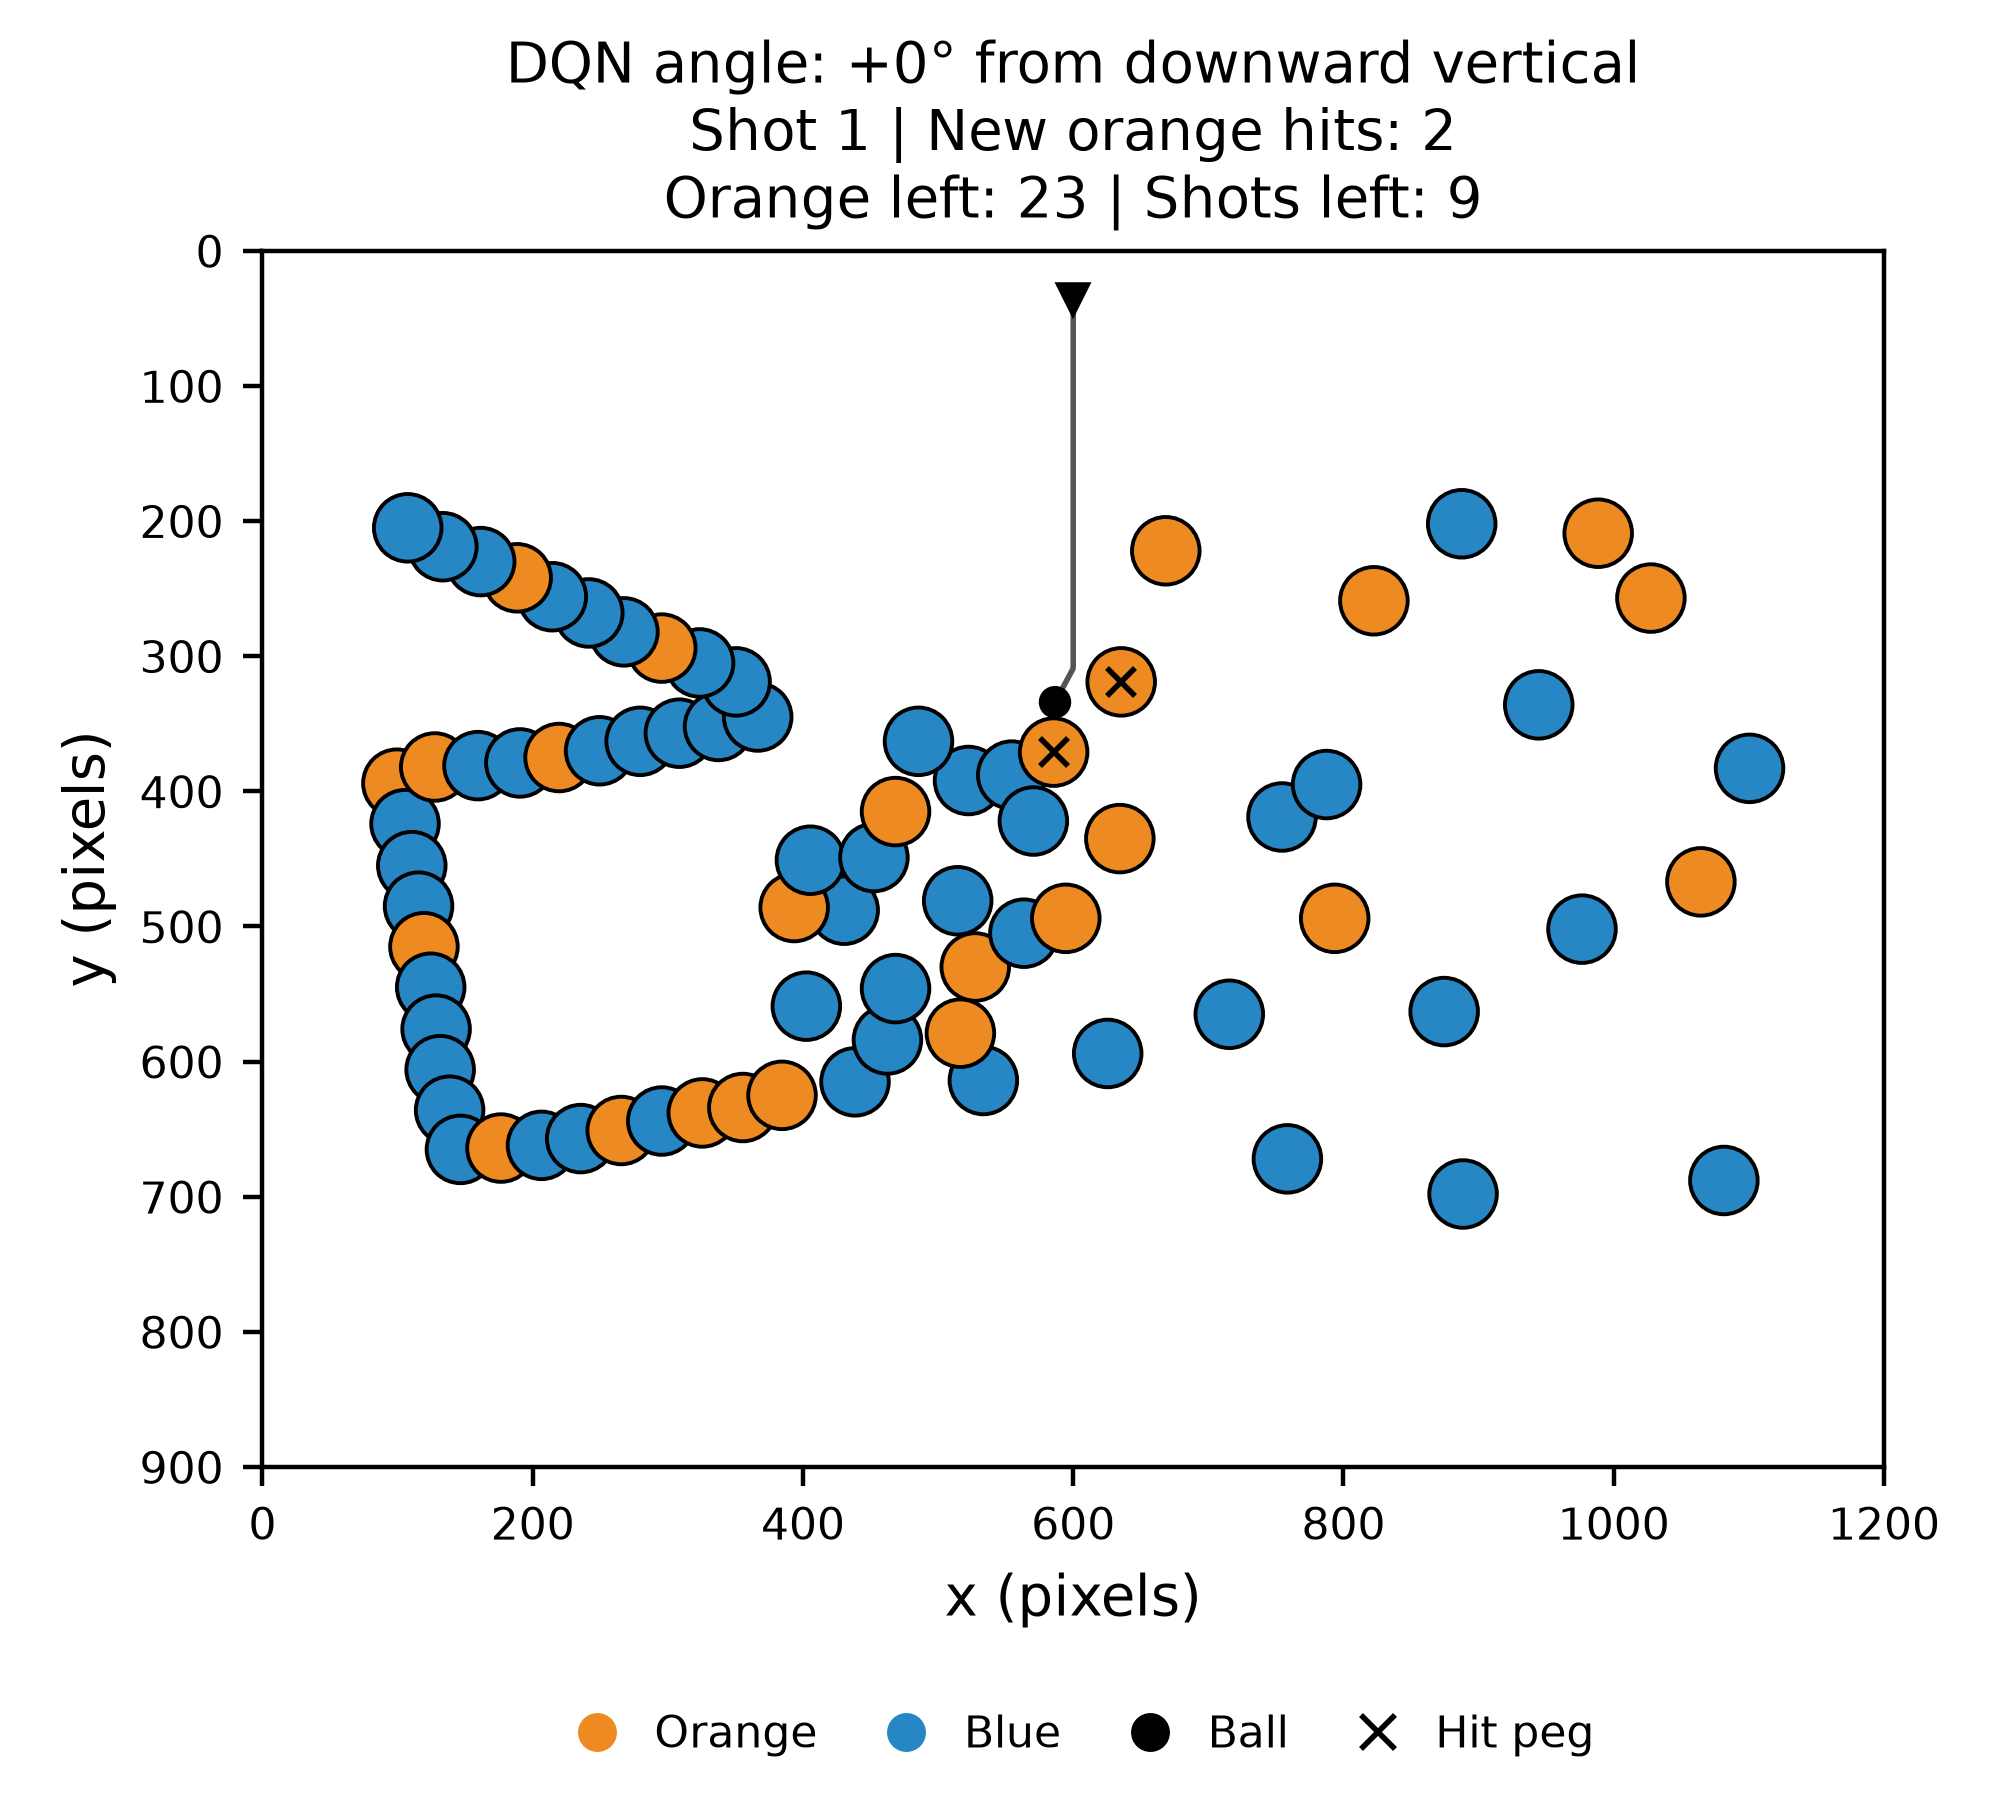

In [12]:
dqn_games = evaluation_episodes[evaluation_episodes.agent == "DQN"]
example = dqn_games.sort_values(["success", "orange_cleared", "shots_used"],
                                ascending=[False, False, True]).iloc[0]
demo_shots, demo_table = record_gameplay(model, int(example.seed), config)
display(demo_table)
assert demo_table.iloc[-1].orange_remaining == example.orange_remaining
measured = shot_log[(shot_log.agent == "DQN") & (shot_log.episode == example.episode)]
np.testing.assert_array_equal(demo_table.angle_degrees, measured.angle_degrees)
result = "WIN" if example.success else "LOSS"
print(f"Recorded evaluation episode {int(example.episode)}, seed {int(example.seed)}: "
      f"{result}; {int(example.orange_remaining)} orange pegs remained.")
shot = demo_shots[0]
trajectory = shot["trajectory"]
frame_index = len(trajectory) // 2
for i, frame in enumerate(trajectory):
    new_hits = sum(peg["color"] == "orange" and frame["is_hit"][j]
                   for j, peg in enumerate(shot["board"]))
    if new_hits >= 2 and frame["ball_alive"]:
        frame_index = i
        break
fig = plot_gameplay(shot["board"], trajectory, frame_index,
    shot["info"]["angle_degrees"], 1, config)
fig.savefig(evaluation_dir / "dqn_gameplay_screenshot.png", dpi=400)
plt.close(fig)
demo_table.to_csv(evaluation_dir / "gameplay_shots.csv", index=False)
display(Image(filename=str(evaluation_dir / "dqn_gameplay_screenshot.png"), width=600))

### Optional replay of the entire recorded game

The animation samples approximately 12 real moments per shot, including every final state, to keep the notebook compact. It is accelerated playback rather than real-time simulation. Set `SHOW_ANIMATION = False` to skip it; the table and screenshot remain available.

In [13]:
from matplotlib.animation import FuncAnimation
SHOW_ANIMATION = True
if SHOW_ANIMATION:
    frames = []
    for number, shot in enumerate(demo_shots):
        count = len(shot["trajectory"])
        for index in range(0, count - 1, max(1, count // 12)):
            frames.append((number, index))
        frames.append((number, count - 1))
    animation_fig, animation_ax = plt.subplots(figsize=(5,4.5))
    def show_frame(pair):
        number, index = pair
        shot = demo_shots[number]
        plot_gameplay(shot["board"], shot["trajectory"], index,
            shot["info"]["angle_degrees"], number + 1, config, ax=animation_ax)
    animation = FuncAnimation(animation_fig, show_frame, frames=frames, interval=60, repeat=False)
    plt.close(animation_fig)
    display(HTML(animation.to_jshtml(default_mode="once")))